# Low-pass filter rekursif Pan-Tompkins: dari difference equation ke fixed-point

Notebook ini menurunkan, membuktikan, dan memplot low-pass filter rekursif Pan-Tompkins.
Setiap angka yang diklaim dihitung di cell tempat angka itu dicetak.

Isi notebook:

1. Difference equation dan definisi seluruh variabel.
2. Transfer function $H(z)$ dan penyederhanaannya menjadi dua moving average.
3. Impulse response, magnitude response, zero, dan DC gain.
4. Worked example dengan tabel per suku: impulse input, rectangular pulse, evaluasi rumus magnitudo.
5. Plot respons magnitudo pada $f_s = 200$ Hz dan pada $f_s = 250$ Hz.
6. Aplikasi pada sinyal ECG 250 Hz dengan noise 50 Hz, baseline wander 0.3 Hz, dan muscle noise.
7. Kesetaraan bentuk recursive dengan bentuk FIR, fixed-point int16, dan bit growth.

## 1. Difference equation

Filter low-pass Pan-Tompkins adalah filter rekursif orde dua dengan numerator sparse:

$$ y[n] = 2 y[n-1] - y[n-2] + x[n] - 2 x[n-6] + x[n-12] $$

Initial condition nol, sesuai implementasi di FPGA dan di MCU saat start:

$$ y[n] = 0 \ \text{untuk} \ n < 0, \qquad x[n] = 0 \ \text{untuk} \ n < 0 $$

Definisi seluruh variabel:

| Simbol | Arti |
|---|---|
| $n$ | indeks sample diskrit, bilangan bulat |
| $T$ | periode sampling, $T = 1/f_s$ |
| $f_s$ | sampling frequency dalam Hz, 200 Hz di paper dan 250 Hz di board tim |
| $x[n]$ | input pada sample $n$, yaitu sinyal ECG mentah dari ADC |
| $y[n]$ | output pada sample $n$, yaitu sinyal setelah low-pass |
| $z^{-1}$ | operator delay satu sample, memetakan $x[n]$ ke $x[n-1]$ |
| $H(z)$ | transfer function, $H(z) = Y(z)/X(z)$ |
| $\omega$ | frekuensi sudut digital, $\omega = 2 \pi f / f_s$ dalam rad/sample |
| $\delta[n]$ | unit impulse, $\delta[0] = 1$ dan $\delta[n] = 0$ untuk $n \neq 0$ |
| $u[n]$ | unit step, $u[n] = 1$ untuk $n \geq 0$ dan $u[n] = 0$ untuk $n < 0$ |
| $h[n]$ | impulse response, yaitu output $y[n]$ saat input $x[n] = \delta[n]$ |

Dua suku $(1 - 2 z^{-1} + z^{-2})$ di ruas kanan adalah feedback, dan tiga suku $x[n] - 2x[n-6] + x[n-12]$ adalah feedforward.
Rasio $6/1$ antara delay feedback dan feedforward inilah yang membuat filter ini menjadi low-pass dengan zero di $f_s/6$.

In [ ]:
# Tujuan: menyiapkan library, konstanta sampling, dan helper filter yang dipakai seluruh notebook.
# Cell ini mencetak versi library, dua frekuensi sampling, koefisien bentuk recursive, dan koefisien bentuk FIR.

%matplotlib inline

import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
from scipy import signal as sg
from scipy.optimize import brentq

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True})
pd.set_option("display.width", 200)

FS_PAPER = 200.0   # sampling frequency paper Pan-Tompkins
FS_BOARD = 250.0   # sampling frequency board tim

# Koefisien bentuk recursive: y[n] = 2y[n-1] - y[n-2] + x[n] - 2x[n-6] + x[n-12]
B_IIR = np.array([1.0, 0.0, 0.0, 0.0, 0.0, 0.0, -2.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0])
A_IIR = np.array([1.0, -2.0, 1.0])

# Koefisien bentuk FIR: kuadrat dari moving average 6 tap, panjang 11 tap
H_FIR = np.convolve(np.ones(6), np.ones(6))


def mag_H(f, fs):
    """Magnitude response |H| = (sin(3*omega)/sin(omega/2))^2, dengan f = 0 dipetakan ke DC gain 36."""
    f = np.asarray(f, dtype=float)
    w = 2.0 * np.pi * f / fs
    with np.errstate(divide="ignore", invalid="ignore"):
        r = np.sin(3.0 * w) / np.sin(w / 2.0)
    out = np.where(np.abs(f) < 1e-12, 36.0, r ** 2)
    return float(out) if out.ndim == 0 else out


def f_3db(fs):
    """Frekuensi titik -3 dB, solusi numerik dari (sin(3w)/sin(w/2))^2 = 36/sqrt(2)."""
    w = brentq(lambda w_: mag_H(w_ * fs / (2.0 * np.pi), fs) - 36.0 / np.sqrt(2.0),
               1e-9, np.pi / 3.0 - 1e-9)
    return w * fs / (2.0 * np.pi)


print("numpy", np.__version__, "| scipy", scipy.__version__, "| pandas", pd.__version__)
print("fs paper =", FS_PAPER, "Hz | fs board =", FS_BOARD, "Hz")
print("B_IIR    =", B_IIR)
print("A_IIR    =", A_IIR)
print("H_FIR    =", H_FIR, "| sum =", H_FIR.sum())

numpy 2.4.6 | scipy 1.17.1 | pandas 2.3.3
fs paper = 200.0 Hz | fs board = 250.0 Hz
B_IIR    = [ 1.  0.  0.  0.  0.  0. -2.  0.  0.  0.  0.  0.  1.]
A_IIR    = [ 1. -2.  1.]
H_FIR    = [1. 2. 3. 4. 5. 6. 5. 4. 3. 2. 1.] | sum = 36.0


## 2. Transfer function

Transformasi z dari kedua sisi difference equation dengan initial condition nol:

$$ Y(z) = 2 z^{-1} Y(z) - z^{-2} Y(z) + X(z) - 2 z^{-6} X(z) + z^{-12} X(z) $$

Kumpulkan $Y(z)$ dan $X(z)$:

$$ Y(z) \left(1 - 2 z^{-1} + z^{-2}\right) = X(z) \left(1 - 2 z^{-6} + z^{-12}\right) $$

$$ H(z) = \frac{Y(z)}{X(z)} = \frac{1 - 2 z^{-6} + z^{-12}}{1 - 2 z^{-1} + z^{-2}} $$

Denominator $1 - 2z^{-1} + z^{-2}$ memiliki akar ganda di $z = 1$, jadi filter ini secara marginal stabil dan hanya terbatas karena zero numerator menghapus pole tersebut secara analitik. Fakta ini dipakai lagi di bagian fixed-point.

In [2]:
# Tujuan: memverifikasi klaim transfer function H(z) = (1 - 2z^-6 + z^-12)/(1 - 2z^-1 + z^-2) pada data.
# Cell ini mencetak galat maksimum identitas Y(z)D(z) = X(z)N(z) dan impulse response hasil rekursi.

rng = np.random.default_rng(11)
x_rand = rng.normal(0.0, 1.0, 64)

y_rec = sg.lfilter(B_IIR, A_IIR, x_rand)      # bentuk recursive
lhs = sg.lfilter(A_IIR, [1.0], y_rec)         # Y(z) D(z) = (1 - 2z^-1 + z^-2) Y(z)
rhs = sg.lfilter(B_IIR, [1.0], x_rand)        # X(z) N(z) = (1 - 2z^-6 + z^-12) X(z)
err_id = np.max(np.abs(lhs - rhs))

imp = np.zeros(24)
imp[0] = 1.0
y_imp = sg.lfilter(B_IIR, A_IIR, imp)

print("koefisien numerator N(z)   =", B_IIR)
print("koefisien denominator D(z) =", A_IIR)
print("galat maksimum Y(z)D(z) - X(z)N(z) =", err_id)
print("impulse response rekursif n = 0..23:")
print(np.array2string(y_imp, precision=2, suppress_small=True))
print("nilai maksimum |y| setelah n = 10 :", np.max(np.abs(y_imp[11:])))

assert err_id < 1e-8, "identitas transfer function tidak terpenuhi"
assert np.max(np.abs(y_imp[11:])) < 1e-12, "tail impulse response tidak nol"
print("lolos: identitas transfer function benar dan impulse response berakhir di n = 10")

koefisien numerator N(z)   = [ 1.  0.  0.  0.  0.  0. -2.  0.  0.  0.  0.  0.  1.]
koefisien denominator D(z) = [ 1. -2.  1.]
galat maksimum Y(z)D(z) - X(z)N(z) = 3.774758283725532e-15
impulse response rekursif n = 0..23:
[1. 2. 3. 4. 5. 6. 5. 4. 3. 2. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
nilai maksimum |y| setelah n = 10 : 0.0
lolos: identitas transfer function benar dan impulse response berakhir di n = 10


## 3. Penyederhanaan

Numerator dan denominator keduanya kuadrat sempurna:

$$ 1 - 2 z^{-6} + z^{-12} = \left(1 - z^{-6}\right)^2, \qquad 1 - 2 z^{-1} + z^{-2} = \left(1 - z^{-1}\right)^2 $$

Faktorkan $1 - z^{-6}$ sebagai deret geometri berjumlah enam suku:

$$ 1 - z^{-6} = \left(1 - z^{-1}\right)\left(1 + z^{-1} + z^{-2} + z^{-3} + z^{-4} + z^{-5}\right) $$

Substitusikan ke $H(z)$, faktor $\left(1 - z^{-1}\right)^2$ saling menghapus:

$$ H(z) = \frac{\left(1 - z^{-1}\right)^2 \left(\sum_{k=0}^{5} z^{-k}\right)^2}{\left(1 - z^{-1}\right)^2} = \left(\sum_{k=0}^{5} z^{-k}\right)^{2} $$

Hasil ini adalah inti pelajaran notebook: bentuk rekursif dengan pole ganda di $z = 1$ identik dengan dua moving average 6 tap yang dikaskade. DC gain keduanya sama, yaitu $6 \times 6 = 36$.

In [3]:
# Tujuan: memverifikasi faktorisasi numerator, denominator, dan bentuk kuadrat moving average 6 tap.
# Cell ini mencetak koefisien tiap faktor dan hasil pemeriksaan kesamaan polinomial.

num = np.convolve([1.0, 0, 0, 0, 0, 0, -1.0], [1.0, 0, 0, 0, 0, 0, -1.0])   # (1 - z^-6)^2
den = np.convolve([1.0, -1.0], [1.0, -1.0])                                # (1 - z^-1)^2
geom = np.convolve([1.0, -1.0], np.ones(6))                                # (1 - z^-1)(1 + ... + z^-5)

print("(1 - z^-6)^2          =", num.astype(int))
print("(1 - z^-1)^2          =", den.astype(int))
print("(1 - z^-1) * MA6      =", geom.astype(int), " -> (1 - z^-6)")
print("(1 - z^-1)^2 * H_FIR  =", np.convolve(den, H_FIR).astype(int))
print("H_FIR                 =", H_FIR.astype(int), " -> (sum z^-k)^2")

assert np.allclose(geom, [1, 0, 0, 0, 0, 0, -1]), "deret geometri tidak konsisten"
assert np.allclose(np.convolve(den, H_FIR), num), "faktorisasi tidak konsisten"
print("lolos: H(z) = (1 - 2z^-6 + z^-12)/(1 - 2z^-1 + z^-2) = (sum dari k=0 sampai 5 z^-k)^2")

(1 - z^-6)^2          = [ 1  0  0  0  0  0 -2  0  0  0  0  0  1]
(1 - z^-1)^2          = [ 1 -2  1]
(1 - z^-1) * MA6      = [ 1  0  0  0  0  0 -1]  -> (1 - z^-6)
(1 - z^-1)^2 * H_FIR  = [ 1  0  0  0  0  0 -2  0  0  0  0  0  1]
H_FIR                 = [1 2 3 4 5 6 5 4 3 2 1]  -> (sum z^-k)^2
lolos: H(z) = (1 - 2z^-6 + z^-12)/(1 - 2z^-1 + z^-2) = (sum dari k=0 sampai 5 z^-k)^2


## 4. Impulse response

Karena $H(z)$ adalah kuadrat dari deret enam tap, $h[n]$ adalah konvolusi $\left[1,1,1,1,1,1\right]$ dengan dirinya sendiri, yaitu sinyal segitiga:

$$ h[n] = (n+1)\left(u[n] - u[n-6]\right) + (11-n)\left(u[n-6] - u[n-11]\right) $$

Bentuk piecewise yang identik:

$$ h[n] = \begin{cases} n+1, & 0 \leq n \leq 5 \\ 11-n, & 6 \leq n \leq 10 \\ 0, & n \geq 11 \end{cases} $$

Jumlah seluruh koefisien sama dengan DC gain:

$$ \sum_{n} h[n] = 1 + 2 + 3 + 4 + 5 + 6 + 5 + 4 + 3 + 2 + 1 = 36 $$

In [4]:
# Tujuan: membandingkan impulse response hasil rekursi dengan rumus segitiga h[n] dan menagih kesamaannya.
# Cell ini mencetak h[n] dari kedua jalur, galat maksimum, indeks peak, dan jumlah koefisien.

n_idx = np.arange(0, 16)
step = lambda k: (k >= 0).astype(float)
h_closed = (n_idx + 1) * (step(n_idx) - step(n_idx - 6)) \
    + (11 - n_idx) * (step(n_idx - 6) - step(n_idx - 11))

imp = np.zeros(len(n_idx))
imp[0] = 1.0
h_rec = sg.lfilter(B_IIR, A_IIR, imp)

print("n                    =", n_idx)
print("h[n] rumus segitiga  =", h_closed.astype(int))
print("h[n] hasil rekursi   =", np.rint(h_rec).astype(int))
print("galat maksimum       =", np.max(np.abs(h_closed - h_rec)))
print("peak index n         =", int(np.argmax(h_closed)), "dengan nilai", int(h_closed.max()))
print("sum h[n]             =", h_closed.sum())

assert np.allclose(h_closed, h_rec, atol=1e-12), "rumus segitiga tidak cocok dengan rekursi"
assert h_closed.sum() == 36.0, "sum h[n] harus 36"
print("lolos: rumus segitiga sama dengan hasil rekursi dan sum h[n] = 36")

n                    = [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15]
h[n] rumus segitiga  = [1 2 3 4 5 6 5 4 3 2 1 0 0 0 0 0]
h[n] hasil rekursi   = [1 2 3 4 5 6 5 4 3 2 1 0 0 0 0 0]
galat maksimum       = 0.0
peak index n         = 5 dengan nilai 6
sum h[n]             = 36.0
lolos: rumus segitiga sama dengan hasil rekursi dan sum h[n] = 36


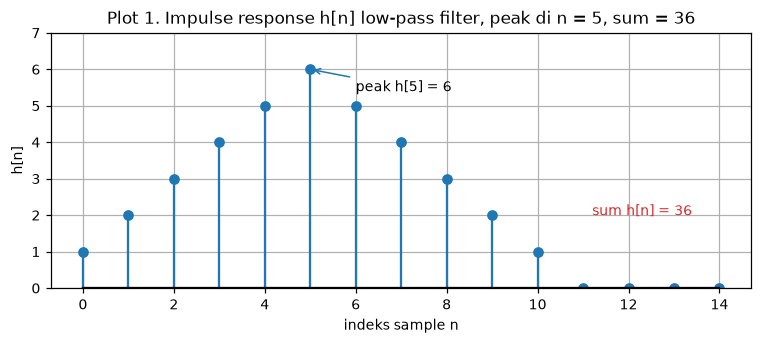

sum h[n] = 36.0 dan peak h[ 5 ] = 6.0


In [5]:
# Tujuan: memplot impulse response h[n] dan menandai peak serta jumlah koefisien.
# Cell ini menampilkan Plot 1 dan mencetak jumlah koefisien yang dianotasi pada gambar.

n_plot = np.arange(0, 15)
h_plot = np.concatenate([H_FIR, np.zeros(len(n_plot) - len(H_FIR))])
peak_idx = int(np.argmax(h_plot))
total = H_FIR.sum()

fig1, ax1 = plt.subplots(figsize=(7.0, 3.2))
ax1.stem(n_plot, h_plot, basefmt="k-", linefmt="C0-", markerfmt="C0o")
ax1.annotate(f"peak h[{peak_idx}] = {h_plot[peak_idx]:.0f}",
             xy=(peak_idx, h_plot[peak_idx]), xytext=(peak_idx + 1.0, h_plot[peak_idx] - 0.6),
             arrowprops=dict(arrowstyle="->", color="C0"))
ax1.annotate(f"sum h[n] = {total:.0f}", xy=(11.2, 2.0), color="C3")
ax1.set_title("Plot 1. Impulse response h[n] low-pass filter, peak di n = "
              f"{peak_idx}, sum = {total:.0f}")
ax1.set_xlabel("indeks sample n")
ax1.set_ylabel("h[n]")
ax1.set_ylim(0, 7)
fig1.tight_layout()
plt.show()
print("sum h[n] =", total, "dan peak h[", peak_idx, "] =", h_plot[peak_idx])

## 5. Magnitude response

Evaluasi $H(z)$ pada lingkaran satuan $z = e^{j\omega}$ dengan $\omega = 2\pi f / f_s$. Deret geometri enam suku memberi:

$$ H(e^{j\omega}) = \left(\frac{\sin(3\omega)}{\sin(\omega/2)}\right)^2 e^{-j 5 \omega} $$

Faktor eksponensial adalah phase linear, jadi magnitude response tinggal magnitude bagian riilnya:

$$ \left|H(e^{j\omega})\right| = \left(\frac{\sin(3\omega)}{\sin(\omega/2)}\right)^{2} $$

Sifat yang dipakai di seluruh notebook:

1. Zero terjadi saat $\sin(3\omega) = 0$, yaitu $\omega = k\pi/3$ atau $f = k f_s / 6$. First zero ada di 33.33 Hz untuk $f_s = 200$ Hz dan di 41.67 Hz untuk $f_s = 250$ Hz.
2. Batas DC: $\lim_{\omega \to 0} \left|H\right| = (3/0.5)^2 = 36$, konsisten dengan $\sum h[n] = 36$.
3. Pangkat dua pada rumus berasal dari dua moving average yang dikaskade, bukan dari operasi magnitude kuadrat pada sinyal.

In [6]:
# Tujuan: memverifikasi rumus magnitude terhadap respons numerik dari freqz.
# Cell ini mencetak galat maksimum rumus (sin(3w)/sin(w/2))^2 terhadap |H| hasil freqz.

w_grid, H_num = sg.freqz(H_FIR, [1.0], worN=4096)
f_grid = w_grid * FS_PAPER / (2.0 * np.pi)
H_form = mag_H(f_grid, FS_PAPER)
err_mag = np.max(np.abs(np.abs(H_num) - H_form))

print("titik uji frekuensi      =", f_grid.size)
print("galat maksimum |freqz| - rumus =", err_mag)
print("|H| rumus di DC           =", mag_H(0.0, FS_PAPER))
print("|H| rumus di 33.33 Hz     =", mag_H(FS_PAPER / 6.0, FS_PAPER))
print("|H| rumus di 50 Hz        =", mag_H(50.0, FS_PAPER))

assert err_mag < 1e-9, "rumus magnitude tidak cocok dengan freqz"
print("lolos: rumus magnitude = (sin(3 omega)/sin(omega/2))^2")

titik uji frekuensi      = 4096
galat maksimum |freqz| - rumus = 2.1316282072803006e-14
|H| rumus di DC           = 36.0
|H| rumus di 33.33 Hz     = 4.137693530244811e-31
|H| rumus di 50 Hz        = 2.0000000000000004
lolos: rumus magnitude = (sin(3 omega)/sin(omega/2))^2


## 6. Worked example dengan tabel per suku

Tiga cell berikut meniru perhitungan tangan. Setiap baris tabel adalah satu sample $n$, dan setiap kolom adalah satu suku dari difference equation:

$$ y[n] = \underbrace{2 y[n-1]}_{\text{feedforward history}} \underbrace{- y[n-2]}_{} + \underbrace{x[n]}_{} \underbrace{- 2 x[n-6]}_{} + \underbrace{x[n-12]}_{} $$

Kolom $y[n]$ adalah jumlah seluruh kolom suku. Index di luar array dianggap 0, sesuai initial condition nol.

### Step A. Impulse input

Input $x[0] = 1$ dan $x[n] = 0$ untuk $n > 0$. Output yang diharapkan adalah impulse response segitiga dari bagian 4.

In [7]:
# Tujuan: menghitung respons impulse input sample per sample dalam tabel per suku, lalu menagihnya terhadap rumus h[n].
# Cell ini mencetak tabel DataFrame satu kolom per suku dan galat terhadap rumus segitiga.

def tabel_rekursi(x_in, n_max):
    """Bangun tabel worked example: satu kolom per suku difference equation."""
    xv = lambda i: 0 if i < 0 else int(x_in[i])
    baris, y_all = [], []
    for n in range(n_max + 1):
        y1 = 0 if n < 1 else y_all[n - 1]
        y2 = 0 if n < 2 else y_all[n - 2]
        yn = 2 * y1 - y2 + xv(n) - 2 * xv(n - 6) + xv(n - 12)
        baris.append({"n": n, "2y[n-1]": 2 * y1, "-y[n-2]": -y2, "x[n]": xv(n),
                      "-2x[n-6]": -2 * xv(n - 6), "x[n-12]": xv(n - 12), "y[n]": yn})
        y_all.append(yn)
    return pd.DataFrame(baris), np.array(y_all, dtype=float)


N_A = 13
x_imp = np.zeros(N_A + 1)
x_imp[0] = 1.0
df_a, y_a = tabel_rekursi(x_imp, N_A)
df_a["h[n] rumus"] = h_closed[:N_A + 1].astype(int)

print("Step A. impulse input x[0] = 1, satu kolom per suku difference equation:")
print(df_a.to_string(index=False))

err_a = np.max(np.abs(y_a - h_closed[:N_A + 1]))
print("output rekursi y[n]      =", y_a.astype(int))
print("impulse response rumus   =", h_closed[:N_A + 1].astype(int))
print("galat maksimum           =", err_a)

assert err_a < 1e-12, "output rekursi berbeda dari rumus segitiga"
assert np.allclose(y_a, sg.lfilter(H_FIR, [1.0], x_imp), atol=1e-12)
print("lolos: output rekursi sama dengan impulse response segitiga")

Step A. impulse input x[0] = 1, satu kolom per suku difference equation:
 n  2y[n-1]  -y[n-2]  x[n]  -2x[n-6]  x[n-12]  y[n]  h[n] rumus
 0        0        0     1         0        0     1           1
 1        2        0     0         0        0     2           2
 2        4       -1     0         0        0     3           3
 3        6       -2     0         0        0     4           4
 4        8       -3     0         0        0     5           5
 5       10       -4     0         0        0     6           6
 6       12       -5     0        -2        0     5           5
 7       10       -6     0         0        0     4           4
 8        8       -5     0         0        0     3           3
 9        6       -4     0         0        0     2           2
10        4       -3     0         0        0     1           1
11        2       -2     0         0        0     0           0
12        0       -1     0         0        1     0           0
13        0        0     0     

### Step B. Rectangular pulse enam sample

Input $x[n] = 1$ untuk $0 \leq n \leq 5$ dan $x[n] = 0$ untuk $n \geq 6$. Output adalah konvolusi pulse dengan segitiga $h[n]$:

$$ y[n] = \sum_{k=0}^{5} h[n-k] = \sum_{j=n-5}^{n} h[j] $$

Nilai maksimum terjadi di $n = 8$ dan sama dengan jumlah $h[3]$ sampai $h[8]$:

$$ y[8] = h[8] + h[7] + h[6] + h[5] + h[4] + h[3] = 4+5+6+5+4+3 = 27 $$

In [8]:
# Tujuan: menghitung respons rectangular pulse enam sample dalam tabel per suku dan menagih nilai maksimumnya.
# Cell ini mencetak tabel DataFrame, nilai peak, dan jumlah h[3] sampai h[8] sebagai pembanding.

N_B = 20
x_pulse = np.zeros(N_B + 1)
x_pulse[0:6] = 1.0
df_b, y_b = tabel_rekursi(x_pulse, N_B)

print("Step B. rectangular pulse x[n] = 1 untuk n = 0 sampai 5, satu kolom per suku:")
print(df_b.to_string(index=False))

peak_b = y_b.max()
idx_b = int(np.argmax(y_b))
sum_h3_8 = float(H_FIR[3:9].sum())
print("nilai maksimum output      =", peak_b, "pada n =", idx_b)
print("sum h[3] sampai h[8]       =", sum_h3_8, "dari h =", H_FIR[3:9].astype(int))
print("galat maksimum vs lfilter  =", np.max(np.abs(y_b - sg.lfilter(H_FIR, [1.0], x_pulse))))

assert np.isclose(peak_b, sum_h3_8), "nilai plateau tidak sama dengan sum h[3..8]"
assert np.isclose(sum_h3_8, 27.0), "sum h[3..8] harus 27"
print("lolos: nilai maksimum y[", idx_b, "] = y[8] =", peak_b, "sama dengan sum h[3..8] =", sum_h3_8)

Step B. rectangular pulse x[n] = 1 untuk n = 0 sampai 5, satu kolom per suku:
 n  2y[n-1]  -y[n-2]  x[n]  -2x[n-6]  x[n-12]  y[n]
 0        0        0     1         0        0     1
 1        2        0     1         0        0     3
 2        6       -1     1         0        0     6
 3       12       -3     1         0        0    10
 4       20       -6     1         0        0    15
 5       30      -10     1         0        0    21
 6       42      -15     0        -2        0    25
 7       50      -21     0        -2        0    27
 8       54      -25     0        -2        0    27
 9       54      -27     0        -2        0    25
10       50      -27     0        -2        0    21
11       42      -25     0        -2        0    15
12       30      -21     0         0        1    10
13       20      -15     0         0        1     6
14       12      -10     0         0        1     3
15        6       -6     0         0        1     1
16        2       -3     0         0  

### Step C. Evaluasi rumus magnitudo secara manual

Dua frekuensi uji pada $f_s = 200$ Hz:

- First zero, $f = f_s/6 = 33.33$ Hz, jadi $\omega = 2\pi/6 = \pi/3$. Numerator $\sin(3\omega) = \sin(\pi) = 0$, maka $\left|H\right| = 0$ secara eksak.
- $f = f_s/4 = 50$ Hz, jadi $\omega = \pi/2$. Numerator $\sin(3\pi/2) = -1$ dan denominator $\sin(\pi/4) = \sqrt{2}/2$, maka $\left|H\right| = \left(-\sqrt{2}\right)^2 = 2$ secara eksak.

Nilai 2 pada 50 Hz setara dengan atenuasi $20 \log_{10}(2/36)$ dB, yaitu sekitar -25.1 dB. Inilah cara filter Pan-Tompkins membuang interferensi mains.

In [9]:
# Tujuan: mengevaluasi rumus magnitude di fs/6 dan fs/4 secara manual, eksak dan numerik.
# Cell ini mencetak nilai sinus, rasio, magnitude untuk kedua frekuensi, plus pemeriksaan eksak akar unity.

fs = FS_PAPER
f_zero, f_quarter = fs / 6.0, fs / 4.0
w_zero, w_quarter = 2.0 * np.pi * f_zero / fs, 2.0 * np.pi * f_quarter / fs

print("evaluasi manual pada fs =", fs, "Hz")
print("f = fs/6 =", f_zero, "Hz -> omega =", w_zero, "rad, 3*omega =", 3 * w_zero)
print("  sin(3 omega) =", np.sin(3 * w_zero), "  sin(omega/2) =", np.sin(w_zero / 2))
print("  rasio        =", np.sin(3 * w_zero) / np.sin(w_zero / 2))
print("  |H| numerik  =", mag_H(f_zero, fs))
print("f = fs/4 =", f_quarter, "Hz -> omega =", w_quarter, "rad, 3*omega =", 3 * w_quarter)
print("  sin(3 omega) =", np.sin(3 * w_quarter), "  sin(omega/2) =", np.sin(w_quarter / 2))
print("  rasio        =", np.sin(3 * w_quarter) / np.sin(w_quarter / 2))
print("  |H| numerik  =", mag_H(f_quarter, fs))
print("  |H| dalam dB =", 20.0 * np.log10(mag_H(f_quarter, fs) / H_FIR.sum()))
print("DC limit |H|   =", mag_H(0.0, fs), " (rumus 3/0.5 pangkat dua)")

# Pemeriksaan eksak: jumlah akar unity orde 6 lewat pasangan konjugat, dengan w^3 = -1 eksak.
w = np.exp(-1j * np.pi / 3.0)
w_cube = -1.0 + 0.0j
s_zero = (1.0 + w_cube) + (w + w * w_cube) + (w * w + (w * w) * w_cube)
mag_zero_exact = s_zero.real ** 2 + s_zero.imag ** 2
# Pemeriksaan eksak pada omega = pi/2: akar unity orde 4 punya komponen bilangan bulat eksak.
s_quarter = (1.0 + 0.0j) + (-1j) + (-1.0 + 0.0j) + (1j) + (1.0 + 0.0j) + (-1j)
mag_quarter_exact = s_quarter.real ** 2 + s_quarter.imag ** 2
print("eksak di fs/6: sum akar unity =", s_zero, "-> |H| =", mag_zero_exact)
print("eksak di fs/4: sum akar unity =", s_quarter, "-> |H| =", mag_quarter_exact)

assert abs(mag_zero_exact) == 0.0, "|H| di fs/6 harus eksak nol"
assert mag_quarter_exact == 2.0, "|H| di fs/4 harus eksak 2"
assert mag_H(f_zero, fs) < 1e-25, "nilai numerik di fs/6 harus mendekati nol"
assert np.isclose(mag_H(f_quarter, fs), 2.0, atol=1e-12), "nilai numerik di fs/4 harus 2"

# Demonstrasi zero di fs/6 pada sinyal waktu: cosine murni 33.33 Hz dilewatkan filter.
tt = np.arange(0, 6.0, 1.0 / fs)
cos_zero = np.cos(2.0 * np.pi * f_zero * tt)
resid = sg.lfilter(H_FIR / H_FIR.sum(), [1.0], cos_zero)[100:]
print("sisa output untuk cosine 33.33 Hz =", np.max(np.abs(resid)), "dari amplitudo 1.0")
assert np.max(np.abs(resid)) < 1e-13, "zero di fs/6 tidak terlihat di domain waktu"
print("lolos: |H| eksak 0 di fs/6 dan eksak 2 di fs/4")

evaluasi manual pada fs = 200.0 Hz
f = fs/6 = 33.333333333333336 Hz -> omega = 1.0471975511965979 rad, 3*omega = 3.1415926535897936
  sin(3 omega) = -3.216245299353273e-16   sin(omega/2) = 0.5
  rasio        = -6.432490598706546e-16
  |H| numerik  = 4.137693530244811e-31
f = fs/4 = 50.0 Hz -> omega = 1.5707963267948966 rad, 3*omega = 4.71238898038469
  sin(3 omega) = -1.0   sin(omega/2) = 0.7071067811865475
  rasio        = -1.4142135623730951
  |H| numerik  = 2.0000000000000004
  |H| dalam dB = -25.105450102066122
DC limit |H|   = 36.0  (rumus 3/0.5 pangkat dua)
eksak di fs/6: sum akar unity = 0j -> |H| = 0.0
eksak di fs/4: sum akar unity = (1-1j) -> |H| = 2.0
sisa output untuk cosine 33.33 Hz = 4.9231452248221785e-14 dari amplitudo 1.0
lolos: |H| eksak 0 di fs/6 dan eksak 2 di fs/4


### Plot 2. Magnitude response pada $f_s = 200$ Hz

Kurva digambar dari rumus analitik dan ditumpuk dengan hasil `freqz` untuk membuktikan keduanya sama.
Gain dinormalisasi ke DC gain 36, sehingga sumbu vertikal adalah gain relatif dalam dB.

fs                        = 200.0 Hz
frekuensi -3 dB terukur   = 10.770742840983068 Hz (gain -3.0102999566397965 dB)
first zero k*fs/6         = 33.333333333333336 Hz
gain pada 50 Hz           = -25.105450102066122 dB
gain pada DC              = -2.7001169063492082e-14 dB


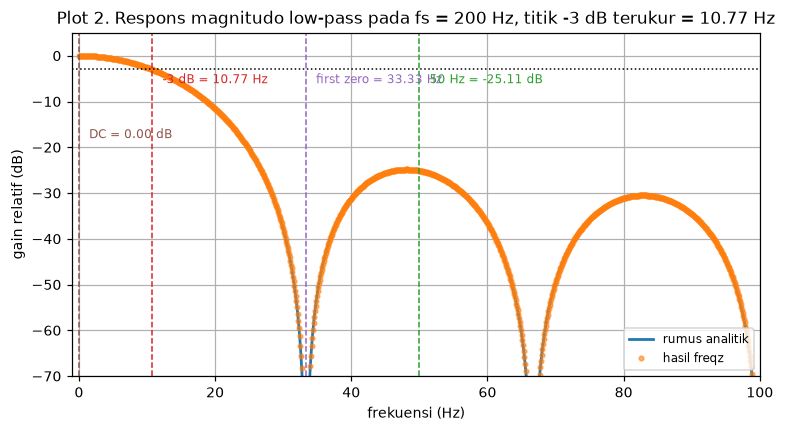

gain pada -3 dB terukur = -3.0102999566397965 dB pada 10.770742840983068 Hz


In [10]:
# Tujuan: memplot magnitude response dB pada fs = 200 Hz dengan anotasi DC, titik -3 dB, zero, dan 50 Hz.
# Cell ini mencetak frekuensi -3 dB hasil pengukuran dan atenuasi pada 50 Hz serta pada first zero.

fs = FS_PAPER
f_plot = np.linspace(0.0, fs / 2.0, 4001)
db_200 = 20.0 * np.log10(mag_H(f_plot, fs) / 36.0)
w_fz, H_fz = sg.freqz(H_FIR, [1.0], worN=1024)
f_fz = w_fz * fs / (2.0 * np.pi)
db_fz = 20.0 * np.log10(np.abs(H_fz) / 36.0)

f_cut_200 = f_3db(fs)
gain_cut = 20.0 * np.log10(mag_H(f_cut_200, fs) / 36.0)
gain_50 = 20.0 * np.log10(mag_H(50.0, fs) / 36.0)

print("fs                        =", fs, "Hz")
print("frekuensi -3 dB terukur   =", f_cut_200, "Hz (gain", gain_cut, "dB)")
print("first zero k*fs/6         =", fs / 6.0, "Hz")
print("gain pada 50 Hz           =", gain_50, "dB")
print("gain pada DC              =", 20.0 * np.log10(mag_H(1e-6, fs) / 36.0), "dB")

assert abs(gain_cut + 3.0103) < 0.01, "titik -3 dB tidak konsisten"
assert np.isclose(mag_H(50.0, fs), 2.0, atol=1e-12), "gain 50 Hz harus 2"

fig2, ax2 = plt.subplots(figsize=(7.2, 4.0))
ax2.plot(f_plot, db_200, "C0-", lw=1.8, label="rumus analitik")
ax2.plot(f_fz, db_fz, "C1o", ms=3, alpha=0.6, label="hasil freqz")
ax2.axhline(-3.0, color="k", ls=":", lw=1.0)
for xv, lab, col in ((f_cut_200, f"-3 dB = {f_cut_200:.2f} Hz", "C3"),
                     (fs / 6.0, f"first zero = {fs / 6.0:.2f} Hz", "C4"),
                     (50.0, f"50 Hz = {gain_50:.2f} dB", "C2"),
                     (0.0, "DC = 0.00 dB", "C5")):
    ax2.axvline(xv, color=col, ls="--", lw=1.0)
    ax2.annotate(lab, xy=(xv, -6.0), xytext=(xv + 1.5, -6.0 - 12.0 * int(xv == 0)),
                 color=col, fontsize=8)
ax2.set_title(f"Plot 2. Respons magnitudo low-pass pada fs = {fs:.0f} Hz, "
              f"titik -3 dB terukur = {f_cut_200:.2f} Hz")
ax2.set_xlabel("frekuensi (Hz)")
ax2.set_ylabel("gain relatif (dB)")
ax2.set_xlim(-1.0, fs / 2.0)
ax2.set_ylim(-70.0, 5.0)
ax2.legend(loc="lower right", fontsize=8)
fig2.tight_layout()
plt.show()
print("gain pada -3 dB terukur =", gain_cut, "dB pada", f_cut_200, "Hz")

## 7. Aplikasi pada sinyal ECG di $f_s = 250$ Hz

Board tim melakukan sampling pada 250 Hz, bukan 200 Hz. Yang perlu diperhatikan:

- Titik -3 dB tidak tetap dalam Hz, tetapi tetap dalam frekuensi ternormalisasi $\omega$. Karena $f = \omega f_s / (2\pi)$, titik -3 dB bergeser sebanding $f_s$, kira-kira dari 10.8 Hz ke 13.5 Hz. Nilai terukurnya dicetak di cell Plot 4.
- First zero bergeser dari 33.33 Hz ke 41.67 Hz, sehingga interferensi mains 50 Hz masuk ke sidelobe pertama filter.
- Filter ini low-pass murni. Baseline wander 0.3 Hz hampir tidak tersentuh, karena itu di Pan-Tompkins tahap high-pass dikerjakan lebih dulu.

Panel PSD memakai `scipy.signal.welch` dan bentuk FIR yang diturunkan di bagian 3, bukan loop manual, dengan group delay 5 sample dikompensasi.

fs = 250.0 Hz | durasi = 20.0 s | jumlah sample = 5000
peak sinyal ECG bersih     = 1.0001005735706738
amplitudo noise 50 Hz      = 0.2
amplitudo baseline wander  = 0.08 pada 0.3 Hz
amplitudo muscle noise     = 0.1 pada band 20 sampai 100 Hz
SNR sebelum filter         = -1.7430898278319218 dB
SNR sesudah filter         = 6.6812864117709205 dB   (perbaikan 8.424376239602843 dB)
korelasi dengan ECG bersih = 0.6360429039804039 -> 0.8885743683584604
daya band 40 sampai 125 Hz = 0.028563059823688793 -> 2.3890013114586914e-05 = -30.775883413235317 dB
atenuasi 50 Hz terukur     = -31.126389847460764 dB, teori = -31.12605001534575 dB
deviasi PSD terhadap teori = median 0.03252121489667679 dB
titik -3 dB pada fs 250 Hz = 13.463428551228837 Hz


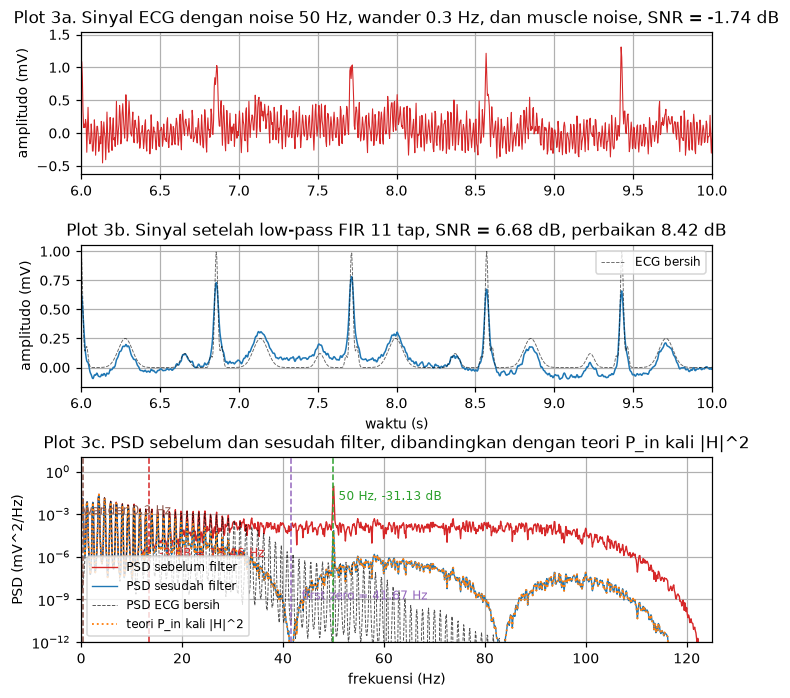

SNR -1.7430898278319218 dB -> 6.6812864117709205 dB, atenuasi 50 Hz -31.126389847460764 dB


In [11]:
# Tujuan: menguji filter pada sinyal ECG sintetis 250 Hz yang terkena noise 50 Hz, baseline wander, dan muscle noise.
# Cell ini mencetak amplitudo tiap noise, SNR sebelum dan sesudah filter, atenuasi 50 Hz terukur,
# galat PSD terhadap teori, lalu menampilkan Plot 3: dua panel waktu dan satu panel PSD.

fs = FS_BOARD
dur = 20.0
t = np.arange(0.0, dur, 1.0 / fs)
rng_ecg = np.random.default_rng(7)

# Sinyal ECG: penjumlahan gelombang P, Q, R, S, T berbentuk Gaussian, heart rate 70 bpm.
hr_bpm = 70.0
beat = 60.0 / hr_bpm
clean = np.zeros_like(t)
for i in range(int(dur / beat)):
    c = i * beat
    for amp, mu, sd in ((0.12, c - 0.20, 0.025), (0.10, c - 0.035, 0.008),
                        (1.00, c, 0.010), (0.18, c + 0.035, 0.009),
                        (0.25, c + 0.28, 0.045)):
        clean += amp * np.exp(-0.5 * ((t - mu) / sd) ** 2)

amp_mains, amp_wander, amp_muscle = 0.20, 0.08, 0.10
mains = amp_mains * np.sin(2.0 * np.pi * 50.0 * t)
wander = amp_wander * np.sin(2.0 * np.pi * 0.3 * t)
band_noise = sg.filtfilt(*sg.butter(2, [20.0 / (fs / 2.0), 100.0 / (fs / 2.0)], btype="band"),
                         rng_ecg.normal(0.0, 1.0, t.size))
muscle = band_noise / band_noise.std() * amp_muscle
noisy = clean + mains + wander + muscle

# Bentuk FIR dari bagian 3, DC gain dinormalisasi ke 1, group delay 5 sample dikompensasi.
H_NORM = H_FIR / H_FIR.sum()
delay = (len(H_FIR) - 1) // 2
y_lp = sg.lfilter(H_NORM, [1.0], noisy)
y_al = np.roll(y_lp, -delay)
sl = slice(200, -200)

snr_before = 10.0 * np.log10(np.var(clean[sl]) / np.var(noisy[sl] - clean[sl]))
snr_after = 10.0 * np.log10(np.var(clean[sl]) / np.var(y_al[sl] - clean[sl]))
corr_before = np.corrcoef(clean[sl], noisy[sl])[0, 1]
corr_after = np.corrcoef(clean[sl], y_al[sl])[0, 1]

# PSD dengan welch, plus overlay teori P_in * |H|^2 untuk membuktikan respons terukur.
f_p, P_noisy = sg.welch(noisy[sl], fs, nperseg=2048)
_, P_filt = sg.welch(y_al[sl], fs, nperseg=2048)
_, P_clean = sg.welch(clean[sl], fs, nperseg=2048)
P_theory = P_noisy * (mag_H(f_p, fs) / H_FIR.sum()) ** 2
band = (f_p >= 1.0) & (f_p <= 100.0) & (np.abs(f_p - fs / 6.0) > 1.5)
dev_db = np.abs(10.0 * np.log10(P_filt[band] / P_theory[band]))
median_dev = float(np.median(dev_db))

i50 = int(np.argmin(np.abs(f_p - 50.0)))
att_50_meas = 10.0 * np.log10(P_filt[i50] / P_noisy[i50])
att_50_theory = 20.0 * np.log10(mag_H(50.0, fs) / H_FIR.sum())
hb = (f_p >= 40.0) & (f_p <= 125.0)
hf_before = np.trapezoid(P_noisy[hb], f_p[hb])
hf_after = np.trapezoid(P_filt[hb], f_p[hb])
f_cut_250 = f_3db(fs)

print("fs =", fs, "Hz | durasi =", dur, "s | jumlah sample =", t.size)
print("peak sinyal ECG bersih     =", np.max(np.abs(clean)))
print("amplitudo noise 50 Hz      =", amp_mains)
print("amplitudo baseline wander  =", amp_wander, "pada 0.3 Hz")
print("amplitudo muscle noise     =", amp_muscle, "pada band 20 sampai 100 Hz")
print("SNR sebelum filter         =", snr_before, "dB")
print("SNR sesudah filter         =", snr_after, "dB   (perbaikan", snr_after - snr_before, "dB)")
print("korelasi dengan ECG bersih =", corr_before, "->", corr_after)
print("daya band 40 sampai 125 Hz =", hf_before, "->", hf_after,
      "=", 10.0 * np.log10(hf_after / hf_before), "dB")
print("atenuasi 50 Hz terukur     =", att_50_meas, "dB, teori =", att_50_theory, "dB")
print("deviasi PSD terhadap teori = median", median_dev, "dB")
print("titik -3 dB pada fs 250 Hz =", f_cut_250, "Hz")

assert snr_after > snr_before, "filter tidak memperbaiki SNR"
assert abs(att_50_meas - att_50_theory) < 0.5, "atenuasi 50 Hz terukur menyimpang dari teori"
assert median_dev < 0.5, "PSD terukur menyimpang dari PSD teori"
assert 13.0 < f_cut_250 < 14.0, "titik -3 dB pada 250 Hz harus di sekitar 13.5 Hz"

fig3, axs = plt.subplots(3, 1, figsize=(7.4, 7.2),
                         gridspec_kw={"height_ratios": [1.0, 1.0, 1.3], "hspace": 0.45})
axs[0].plot(t, noisy, "C3-", lw=0.7)
axs[0].set_title(f"Plot 3a. Sinyal ECG dengan noise 50 Hz, wander 0.3 Hz, dan muscle noise, "
                 f"SNR = {snr_before:.2f} dB")
axs[0].set_ylabel("amplitudo (mV)")
axs[1].plot(t, y_al, "C0-", lw=1.0)
axs[1].plot(t, clean, "k--", lw=0.6, alpha=0.6, label="ECG bersih")
axs[1].set_title(f"Plot 3b. Sinyal setelah low-pass FIR 11 tap, SNR = {snr_after:.2f} dB, "
                 f"perbaikan {snr_after - snr_before:.2f} dB")
axs[1].set_ylabel("amplitudo (mV)")
axs[1].set_xlabel("waktu (s)")
axs[1].legend(loc="upper right", fontsize=8)
for ax in axs[:2]:
    ax.set_xlim(6.0, 10.0)
axs[2].semilogy(f_p, P_noisy, "C3-", lw=0.9, label="PSD sebelum filter")
axs[2].semilogy(f_p, P_filt, "C0-", lw=0.9, label="PSD sesudah filter")
axs[2].semilogy(f_p, P_clean, "k--", lw=0.6, alpha=0.7, label="PSD ECG bersih")
axs[2].semilogy(f_p, P_theory, "C1:", lw=1.2, label="teori P_in kali |H|^2")
axs[2].axvline(0.3, color="C5", ls="--", lw=1.0)
axs[2].annotate("wander 0.3 Hz", xy=(0.3, 1e-3), color="C5", fontsize=8)
axs[2].axvline(50.0, color="C2", ls="--", lw=1.0)
axs[2].annotate(f"50 Hz, {att_50_meas:.2f} dB", xy=(51.0, 1e-2), color="C2", fontsize=8)
axs[2].axvline(f_cut_250, color="C3", ls="--", lw=1.0)
axs[2].annotate(f"-3 dB = {f_cut_250:.2f} Hz", xy=(f_cut_250 + 2.0, 1e-6), color="C3", fontsize=8)
axs[2].axvline(fs / 6.0, color="C4", ls="--", lw=1.0)
axs[2].annotate(f"first zero = {fs / 6.0:.2f} Hz", xy=(fs / 6.0 + 2.0, 1e-9), color="C4", fontsize=8)
axs[2].set_title("Plot 3c. PSD sebelum dan sesudah filter, dibandingkan dengan teori P_in kali |H|^2")
axs[2].set_xlabel("frekuensi (Hz)")
axs[2].set_ylabel("PSD (mV^2/Hz)")
axs[2].set_xlim(0.0, 125.0)
axs[2].set_ylim(1e-12, 1e1)
axs[2].legend(loc="lower left", fontsize=8)
plt.show()
print("SNR", snr_before, "dB ->", snr_after, "dB, atenuasi 50 Hz", att_50_meas, "dB")

titik -3 dB pada fs = 250.0 Hz : 13.463428551228837 Hz
titik -3 dB pada fs = 200.0 Hz : 10.770742840983068 Hz
pergeseran titik -3 dB            : 2.692685710245769 Hz
rasio pergeseran terhadap fs      : 1.25
first zero pada fs = 250.0 Hz : 41.666666666666664 Hz
gain pada 50 Hz, fs = 250.0 Hz: -31.12605001534575 dB
gain pada 50 Hz, fs = 200.0 Hz: -25.105450102066122 dB


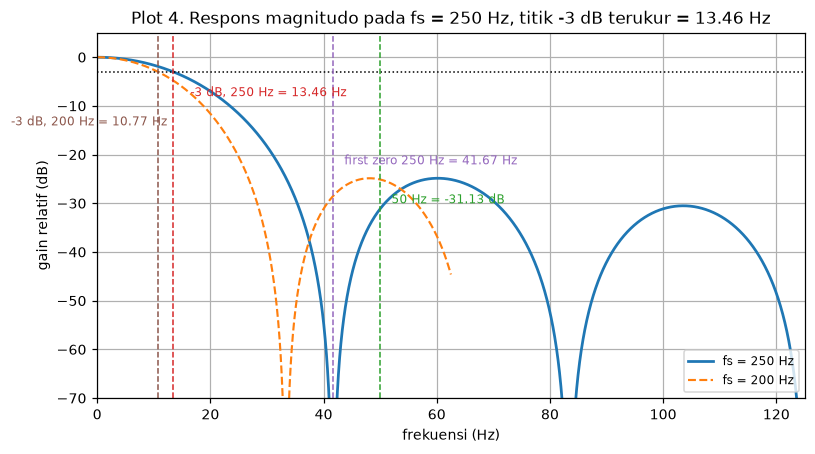

titik -3 dB terukur pada 250 Hz = 13.463428551228837 Hz (200 Hz: 10.770742840983068 Hz)


In [12]:
# Tujuan: memplot magnitude response pada fs = 250 Hz dan menunjukkan pergeseran titik -3 dB dari 200 Hz.
# Cell ini mencetak titik -3 dB pada kedua frekuensi sampling, atenuasi 50 Hz, dan posisi first zero.

f_plot = np.linspace(0.0, FS_BOARD / 2.0, 4001)
f_cut_250 = f_3db(FS_BOARD)
f_cut_200 = f_3db(FS_PAPER)
gain_50_250 = 20.0 * np.log10(mag_H(50.0, FS_BOARD) / 36.0)

print("titik -3 dB pada fs =", FS_BOARD, "Hz :", f_cut_250, "Hz")
print("titik -3 dB pada fs =", FS_PAPER, "Hz :", f_cut_200, "Hz")
print("pergeseran titik -3 dB            :", f_cut_250 - f_cut_200, "Hz")
print("rasio pergeseran terhadap fs      :", FS_BOARD / FS_PAPER)
print("first zero pada fs =", FS_BOARD, "Hz :", FS_BOARD / 6.0, "Hz")
print("gain pada 50 Hz, fs =", FS_BOARD, "Hz:", gain_50_250, "dB")
print("gain pada 50 Hz, fs =", FS_PAPER, "Hz:", 20.0 * np.log10(mag_H(50.0, FS_PAPER) / 36.0), "dB")

assert 13.0 < f_cut_250 < 14.0, "titik -3 dB pada 250 Hz harus di sekitar 13.5 Hz"
assert np.isclose(f_cut_250 / f_cut_200, FS_BOARD / FS_PAPER, rtol=1e-6), "rasio cutoff tidak mengikuti fs"
assert np.isclose(mag_H(50.0, FS_BOARD), 1.0, atol=1e-12), "gain 50 Hz pada 250 Hz harus 1"

fig4, ax4 = plt.subplots(figsize=(7.4, 4.2))
ax4.plot(f_plot, 20.0 * np.log10(mag_H(f_plot, FS_BOARD) / 36.0), "C0-", lw=1.8,
         label=f"fs = {FS_BOARD:.0f} Hz")
ax4.plot(f_plot[:2001], 20.0 * np.log10(mag_H(f_plot[:2001], FS_PAPER) / 36.0), "C1--", lw=1.4,
         label=f"fs = {FS_PAPER:.0f} Hz")
ax4.axhline(-3.0, color="k", ls=":", lw=1.0)
ax4.axvline(f_cut_250, color="C3", ls="--", lw=1.0)
ax4.annotate(f"-3 dB, 250 Hz = {f_cut_250:.2f} Hz", xy=(f_cut_250, -8.0),
             xytext=(f_cut_250 + 3.0, -8.0), color="C3", fontsize=8)
ax4.axvline(f_cut_200, color="C5", ls="--", lw=1.0)
ax4.annotate(f"-3 dB, 200 Hz = {f_cut_200:.2f} Hz", xy=(f_cut_200, -14.0),
             xytext=(f_cut_200 - 26.0, -14.0), color="C5", fontsize=8)
ax4.axvline(FS_BOARD / 6.0, color="C4", ls="--", lw=1.0)
ax4.annotate(f"first zero 250 Hz = {FS_BOARD / 6.0:.2f} Hz", xy=(FS_BOARD / 6.0, -22.0),
             xytext=(FS_BOARD / 6.0 + 2.0, -22.0), color="C4", fontsize=8)
ax4.axvline(50.0, color="C2", ls="--", lw=1.0)
ax4.annotate(f"50 Hz = {gain_50_250:.2f} dB", xy=(50.0, -30.0), xytext=(52.0, -30.0),
             color="C2", fontsize=8)
ax4.set_title(f"Plot 4. Respons magnitudo pada fs = {FS_BOARD:.0f} Hz, "
              f"titik -3 dB terukur = {f_cut_250:.2f} Hz")
ax4.set_xlabel("frekuensi (Hz)")
ax4.set_ylabel("gain relatif (dB)")
ax4.set_xlim(0.0, FS_BOARD / 2.0)
ax4.set_ylim(-70.0, 5.0)
ax4.legend(loc="lower right", fontsize=8)
fig4.tight_layout()
plt.show()
print("titik -3 dB terukur pada 250 Hz =", f_cut_250, "Hz (200 Hz:", f_cut_200, "Hz)")

## 8. Kesetaraan bentuk recursive dan bentuk FIR

Bagian 3 sudah membuktikan secara aljabar bahwa bentuk rekursif sama dengan dua moving average 6 tap. Sekarang dibuktikan secara numerik, termasuk pada data integer dan pada fixed-point.

Pelajaran untuk implementasi di FPGA dan RTL:

- Bentuk FIR, yaitu dua moving average, tidak punya pole, jadi tidak butuh pembatalan apapun dan aman terhadap pembulatan.
- Bentuk rekursif punya pole ganda di $z = 1$ tepat di lingkaran satuan. Pole itu hanya saling menghapus dengan zero numerator pada aritmetika eksak. Begitu state disimpan dalam register dengan jumlah bit terbatas, sisa pembulatan menumpuk di pole tersebut dan output melayang dari output FIR.
- DC gain 36 menambah $\log_2 36 = 5.17$ bit pertumbuhan, sehingga accumulato dan state rekursif harus lebih lebar dari data input.

Kesimpulan praktis: di RTL pakai bentuk FIR dua moving average dengan akumulator lebar, dan pakai bentuk rekursif hanya sebagai deskripsi matematis.

In [13]:
# Tujuan: membuktikan bentuk recursive dan bentuk FIR memberi output identik pada input yang sama.
# Cell ini mencetak galat maksimum kedua bentuk pada input acak dan pada sinyal ECG, serta pada dua moving average.

rng_eq = np.random.default_rng(23)
x_eq = rng_eq.normal(0.0, 1.0, 4000)
y_iir_rand = sg.lfilter(B_IIR, A_IIR, x_eq)
y_fir_rand = sg.lfilter(H_FIR, [1.0], x_eq)
d_rand = float(np.max(np.abs(y_iir_rand - y_fir_rand)))

y_iir_ecg = sg.lfilter(B_IIR, A_IIR, noisy)
y_fir_ecg = sg.lfilter(H_FIR, [1.0], noisy)
d_ecg = float(np.max(np.abs(y_iir_ecg - y_fir_ecg)))
rel_ecg = d_ecg / np.max(np.abs(y_fir_ecg))

two_ma = sg.lfilter(np.ones(6), [1.0], sg.lfilter(np.ones(6), [1.0], x_eq))
d_ma = float(np.max(np.abs(two_ma - y_fir_rand)))

print("input acak, galat maksimum recursive vs FIR      =", d_rand)
print("sinyal ECG, galat maksimum recursive vs FIR      =", d_ecg, "(relatif", rel_ecg, ")")
print("dua moving average 6 tap vs koefisien FIR        =", d_ma)
x_step = np.ones(64)
dc_fir = float(sg.lfilter(H_FIR, [1.0], x_step)[-1])
dc_iir = float(sg.lfilter(B_IIR, A_IIR, x_step)[-1])
print("DC gain bentuk FIR, step input                  =", dc_fir)
print("DC gain bentuk recursive, step input            =", dc_iir)

assert d_rand < 1e-8 and d_ecg < 1e-8, "bentuk recursive tidak sama dengan bentuk FIR"
assert d_ma < 1e-8, "dua moving average tidak sama dengan koefisien FIR"
assert np.isclose(dc_fir, 36.0) and np.isclose(dc_iir, 36.0), "DC gain kedua bentuk harus 36"
print("lolos: kedua bentuk identik secara numerik dengan toleransi 1e-8")

input acak, galat maksimum recursive vs FIR      = 7.228884157939319e-11
sinyal ECG, galat maksimum recursive vs FIR      = 1.7723600365116e-11 (relatif 6.15768501105399e-13 )
dua moving average 6 tap vs koefisien FIR        = 1.0658141036401503e-14
DC gain bentuk FIR, step input                  = 36.0
DC gain bentuk recursive, step input            = 36.0
lolos: kedua bentuk identik secara numerik dengan toleransi 1e-8


In [14]:
# Tujuan: menunjukkan perilaku bentuk recursive saat input dan state dipaksa fixed-point int16.
# Cell ini mencetak galat maksimum recursive terhadap FIR untuk aritmetika float64 dan untuk register int16,
# serta jumlah bit yang dibutuhkan state rekursif.

def rekursi_fixed_point(x_int, bits):
    """Bentuk recursive dengan accumulator yang wrap pada lebar `bits` bit."""
    lo, span = -(1 << (bits - 1)), (1 << bits)
    xb = x_int.astype(np.int64)
    y_fp = np.zeros(len(xb), dtype=np.int64)
    ambil = lambda i: 0 if i < 0 else int(xb[i])
    for n in range(len(xb)):
        v = (2 * (0 if n < 1 else y_fp[n - 1]) - (0 if n < 2 else y_fp[n - 2])
             + ambil(n) - 2 * ambil(n - 6) + ambil(n - 12))
        y_fp[n] = ((v - lo) % span) + lo
    return y_fp


scale = 0.9 * 32767.0 / np.max(np.abs(noisy))
x_q = np.rint(noisy * scale).astype(np.int16)
y_ref = sg.lfilter(H_FIR, [1.0], x_q.astype(np.float64))
d_float = float(np.max(np.abs(sg.lfilter(B_IIR, A_IIR, x_q.astype(np.float64)) - y_ref)))
y_fp16 = rekursi_fixed_point(x_q, 16)
d_fp16 = float(np.max(np.abs(y_fp16.astype(np.float64) - y_ref)))

print("skala ADC int16                =", scale, "count per unit sinyal")
print("peak |x| int16                 =", int(np.max(np.abs(x_q))))
print("peak |y| FIR                   =", float(np.max(np.abs(y_ref))))
print("recursive float64 vs FIR       =", d_float)
print("recursive register int16 vs FIR =", d_fp16)
print("state int16 pertama berbeda pada n =",
      int(np.argmax(np.abs(y_fp16.astype(np.float64) - y_ref) > 0)),
      "karena 2*y[n-1] =", 2 * int(np.max(np.abs(x_q))), "melebihi batas int16 32767")
print("bit minimum untuk menampung |y| =", int(np.ceil(np.log2(np.max(np.abs(y_ref)) + 1.0))))
# Pole ganda di z = 1 hanya saling menghapus pada aritmetika eksak.
print("catatan: pole ganda di z = 1 hanya terhapus pada aritmetika eksak, register int16 menyimpan sisa pembulatan dan output melayang")

assert d_float == 0.0, "aritmetika float64 pada data integer harus eksak"
assert d_fp16 > 1000.0, "register int16 seharusnya menunjukkan drift besar"
print("lolos: aritmetika eksak memberi galat 0, register int16 memberi drift", d_fp16)

skala ADC int16                = 20545.775149665184 count per unit sinyal
peak |x| int16                 = 29490
peak |y| FIR                   = 591371.0
recursive float64 vs FIR       = 0.0
recursive register int16 vs FIR = 589824.0
state int16 pertama berbeda pada n = 1 karena 2*y[n-1] = 58980 melebihi batas int16 32767
bit minimum untuk menampung |y| = 20
catatan: pole ganda di z = 1 hanya terhapus pada aritmetika eksak, register int16 menyimpan sisa pembulatan dan output melayang
lolos: aritmetika eksak memberi galat 0, register int16 memberi drift 589824.0


In [15]:
# Tujuan: menghitung pertumbuhan bit yang dibutuhkan oleh DC gain 36.
# Cell ini mencetak log2 DC gain, bit growth tambahan, dan word length minimum hasil pengukuran.

dc_gain = float(H_FIR.sum())
bit_growth = float(np.log2(dc_gain))
peak_out = float(np.max(np.abs(y_ref)))
bit_out = int(np.ceil(np.log2(peak_out + 1.0)))
bit_in = 15

print("DC gain                     =", dc_gain)
print("log2(DC gain)               =", bit_growth, "bit")
print("data input int16            =", bit_in, "bit magnitude plus sign")
print("peak |y| terukur            =", peak_out)
print("bit minimum untuk |y|       =", bit_out, "bit")
worst_case = int(np.ceil(bit_in + bit_growth))
print("word length data + growth   =", bit_in, "+", round(bit_growth, 2), "=", bit_in + bit_growth,
      "-> worst case", worst_case, "bit")
print("word length hasil pengukuran =", bit_out, "bit (peak input dan peak FIR tidak bertumpuk)")

assert np.isclose(bit_growth, 5.169925001442312, atol=1e-12), "log2(36) salah"
assert worst_case == 21, "worst case word length harus 21 bit"
assert bit_out <= worst_case, "pengukuran tidak boleh melebihi worst case teori"
print("lolos: DC gain 36 menambah", bit_growth, "bit, worst case", worst_case,
      "bit, terukur", bit_out, "bit")

DC gain                     = 36.0
log2(DC gain)               = 5.169925001442312 bit
data input int16            = 15 bit magnitude plus sign
peak |y| terukur            = 591371.0
bit minimum untuk |y|       = 20 bit
word length data + growth   = 15 + 5.17 = 20.169925001442312 -> worst case 21 bit
word length hasil pengukuran = 20 bit (peak input dan peak FIR tidak bertumpuk)
lolos: DC gain 36 menambah 5.169925001442312 bit, worst case 21 bit, terukur 20 bit


## 9. Ringkasan

- Difference equation $y[n] = 2y[n-1] - y[n-2] + x[n] - 2x[n-6] + x[n-12]$ identik dengan $H(z) = \left(\sum_{k=0}^{5} z^{-k}\right)^2$.
- Impulse response segitiga $h[n]$ berakhir di $n = 10$ dengan jumlah 36, dan rumus magnitude $\left(\sin(3\omega)/\sin(\omega/2)\right)^2$ cocok dengan hasil `freqz` sampai galat mesin.
- Titik -3 dB mengikuti frekuensi ternormalisasi, sehingga nilainya berubah dari sekitar 10.8 Hz pada 200 Hz ke sekitar 13.5 Hz pada 250 Hz. Nilai persisnya dicetak di Plot 2 dan Plot 4.
- Filter ini membuang mains 50 Hz dan muscle noise, tetapi baseline wander 0.3 Hz lolos. Tahap high-pass pada rantai Pan-Tompkins yang menangani wander tersebut.
- Bentuk FIR dua moving average 6 tap aman untuk RTL. Bentuk rekursif hanya benar pada aritmetika eksak, dan DC gain 36 menambah 5.17 bit pertumbuhan.